### EasyOCR

/opt/miniconda3/envs/VC_P4/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



Texto: Recuento de puntos (método de victoria opcional)
Probabilidad: 0.76
Contenedor: ((96, 36), (1094, 108))

Texto: Cuando un jugador gana una mano; recibe puntos en función de las cartas que quedan
Probabilidad: 0.84
Contenedor: ((90, 118), (1518, 192))

Texto: en las
Probabilidad: 0.93
Contenedor: ((1513, 155), (1589, 199))

Texto: manos de sus oponentes.
Probabilidad: 0.83
Contenedor: ((94, 176), (528, 226))

Texto: Las cartas se valoran de la siguiente manera:
Probabilidad: 0.97
Contenedor: ((86, 250), (850, 306))

Texto: Cartas del 1al 9
Probabilidad: 1.00
Contenedor: ((236, 328), (516, 376))

Texto: Su valor numérico
Probabilidad: 1.00
Contenedor: ((990, 338), (1304, 386))

Texto: Roba una
Probabilidad: 0.82
Contenedor: ((231, 391), (403, 435))

Texto: 10 puntos
Probabilidad: 1.00
Contenedor: ((994, 398), (1175, 450))

Texto: Roba cinco; Cambio de sentido
Probabilidad: 0.86
Contenedor: ((228, 450), (774, 500))

Texto: Pierde el turno, Flip
Probabilidad: 0.50
Contenedor: ((226

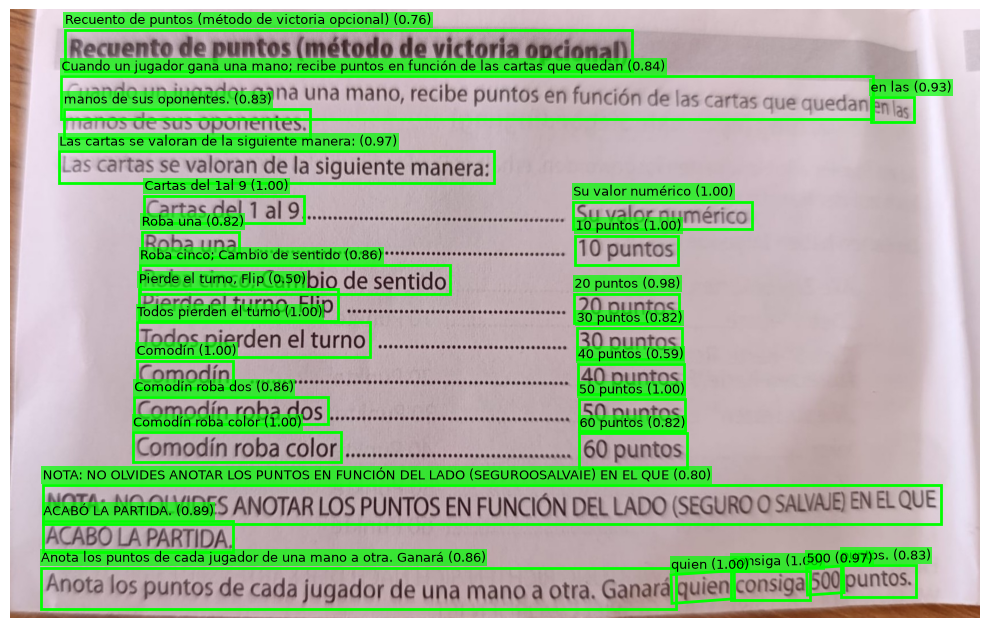

In [1]:
import easyocr
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Carga del modelo de lengua
reader = easyocr.Reader(['es'])
path_image = 'Test.jpg'

# Reconocimiento de una imagen
res = reader.readtext(path_image)

#Con restricción de caracteres reconocibles
#result = reader.readtext(path_image, allowlist ='0123456789')

# Preparar la figura con la imagen
img = plt.imread(path_image)
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
ax.axis('off')

for (bbox, text, prob) in res:
    (top_left, top_right, bottom_right, bottom_left) = bbox
    print(f'\nTexto: {text}\nProbabilidad: {prob:.2f}\n'
          f'Contenedor: {tuple(map(int, top_left)), tuple(map(int, bottom_right))}')

    # Recuadro alrededor del texto detectado
    ax.add_patch(patches.Polygon(bbox, closed=True, fill=False,
                                 edgecolor='lime', linewidth=2))

    # Texto reconocido, justo encima del recuadro
    ax.text(top_left[0], top_left[1] - 5, f'{text} ({prob:.2f})',
            color='black', fontsize=9, va='bottom',
            bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

plt.tight_layout()
plt.savefig(path_image.replace('.jpg', '_output_Easy_OCR.jpg'), dpi=300, bbox_inches='tight')
plt.show()

### Tesseract

In [2]:

# Tesseract
import cv2
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Si la ruta de Tesseract no está en el PATH, ruta al ejecutable
pytesseract.pytesseract.tesseract_cmd = r'/opt/miniconda3/envs/VC_P4/bin/pytesseract'

# Lenguajes disponibles
print(pytesseract.get_languages(config=''))

path_image = 'Test.jpg'
img = cv2.imread(path_image)

if img is not None:
    # Convierte a RGB antes de procesar
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Texto completo
    print(pytesseract.image_to_string(img_rgb, lang='spa'))

    # Texto y localización de cada palabra
    d = pytesseract.image_to_data(img_rgb, lang='spa', output_type=Output.DICT)

    # Preparar la figura con la imagen
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img_rgb)
    ax.axis('off')

    n_boxes = len(d['text'])
    for i in range(n_boxes):
        text = d['text'][i].strip()
        conf = float(d['conf'][i])

        # Ignorar detecciones vacías o poco fiables
        if conf > 30 and text:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])

            print(f'Texto: {text} ({conf:.2f}%)\nContenedor: {x, y, x + w, y + h}')

            # Recuadro alrededor de la palabra
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False,
                                           edgecolor='lime', linewidth=2))

            # Palabra reconocida, justo encima del recuadro
            ax.text(x, y - 3, text, color='black', fontsize=9, va='bottom',
                    bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

    plt.tight_layout()
    plt.savefig(path_image.replace('.jpg', '_output_Tesseract.jpg'), dpi=200, bbox_inches='tight')  # guarda el resultado
    plt.show()

else:
    print('Error de imagen')

[]


TesseractError: (2, 'Usage: pytesseract [-l lang] input_file')

### PaddleOCR

/opt/miniconda3/envs/VC_P4/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/w3/zv8n3jld5fs4l0f5cm30qgqw0000gn/T/ipykernel_61688/1110255119.py:6: DeprecationWarning: The parameter `use_angle_cls` has been deprecated and will be removed in the future. Please use `use_textline_orientation` instead.
  ocr = PaddleOCR(use_angle_cls=True, lang='es')  # need to run only once to download and load model into memory
/opt/miniconda3/envs/VC_P4/lib/python3.11/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)

['Esto es una prueba para', 'Gos OCR. Mi letra no es', 'ser pedr, podria poner aqur', 'Ibupofene y no sabertko.'] [0.9476354122161865, 0.9056820869445801, 0.8573837876319885, 0.8648439049720764]

Text: Esto es una prueba para
Probability: 0.95
Box: ((117, 126), (1920, 393))

Text: Gos OCR. Mi letra no es
Probability: 0.91
Box: ((71, 364), (1815, 690))

Text: ser pedr, podria poner aqur
Probability: 0.86
Box: ((0, 941), (1678, 1308))

Text: Ibupofene y no sabertko.
Probability: 0.86
Box: ((0, 1252), (1529, 1536))


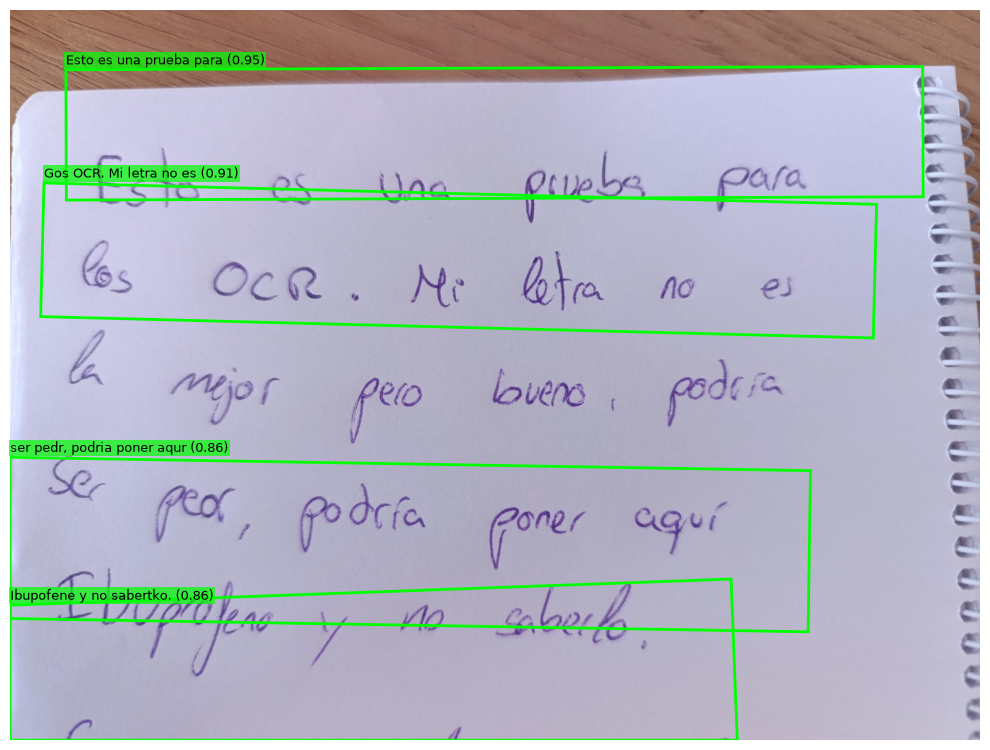

In [2]:
#https://github.com/PADDLEPADDLE/PADDLEOCR
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt
import matplotlib.patches as patches

ocr = PaddleOCR(use_angle_cls=True, lang='es')  # need to run only once to download and load model into memory
img_path = 'Test_manual.jpg'
result = ocr.predict(img_path)[0]

texts = result['rec_texts']
scores = result['rec_scores']
polys = result['rec_polys']  # one 4-point polygon per recognized text

print(texts, scores)

# Prepare the figure with the image
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(plt.imread(img_path))
ax.axis('off')

for poly, text, score in zip(polys, texts, scores):
    print(f'\nText: {text}\nProbability: {score:.2f}\n'
          f'Box: {tuple(map(int, poly[0])), tuple(map(int, poly[2]))}')

    # Box around the detected text
    ax.add_patch(patches.Polygon(poly, closed=True, fill=False,
                                 edgecolor='lime', linewidth=2))

    # Recognized text, just above the top-left corner of the box
    x, y = poly[0]
    ax.text(x, y - 5, f'{text} ({score:.2f})',
            color='black', fontsize=9, va='bottom',
            bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

plt.tight_layout()
plt.savefig(img_path.replace('.jpg', '_output_Paddle.jpg'), dpi=200, bbox_inches='tight')  # save the result
plt.show()

### Unlimited-OCR Baidu

In [1]:
# https://github.com/baidu/Unlimited-OCR
import os
import torch
from transformers import AutoModel, AutoTokenizer

# Para que funcione con respecto al de SmolVLM.

# pip install addict
# pip install einops
# pip install easydict
# pip install transformers==4.57.1
 

# Aparentemente tienen llamadas a cuda en el proceso de inferencia, por lo que si no tenemos GPU falla.
# Vamos a hacer que esas llamadas sean no-ops si no hay GPU disponible. 
if not torch.cuda.is_available():
    torch.Tensor.cuda = lambda self, *a, **k: self
    torch.nn.Module.cuda = lambda self, *a, **k: self
    
model_name = 'baidu/Unlimited-OCR'
path_image = 'Test.jpg'
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_safetensors=True,
    torch_dtype=torch.bfloat16,
)
model = model.eval().cuda()

# ── Single image supports two configs: gundam or base ──
# gundam: base_size=1024, image_size=640, crop_mode=True
# base: base_size=1024, image_size=1024, crop_mode=False
model.infer(
    tokenizer,
    prompt='<image>document parsing.',
    image_file=path_image,
    output_path=path_image.replace('.jpg', '_output_Unlimited'),
    base_size=1024, image_size=640, crop_mode=True,
    max_length=32768,
    no_repeat_ngram_size=35, ngram_window=128,
    save_results=True,
)



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/miniconda3/envs/VC_P4/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/miniconda3/envs/VC_P4/lib/python3.11/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/miniconda3/envs/VC_P4/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 807, in start
    self.io_loop.start()
  File 

KeyboardInterrupt: 

### SmolVLM

In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch
Device = "cpu"  # or "cpu"

processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-Instruct")
model = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-Instruct",
                                                dtype=torch.bfloat16,
                                                _attn_implementation="flash_attention_2" if Device == "cuda" else "eager").to(Device)

from PIL import Image
from transformers.image_utils import load_image
from matplotlib import pyplot as plt

# Load images

image_1 = Image.open('matricula.jpg')
# Create input messages
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": "Can you give me the text in the license plate of the image?"}
        ]
    },
]

# Prepare inputs
prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
inputs = processor(text=prompt, images=[image_1], return_tensors="pt")
inputs = inputs.to(Device)

generated_ids = model.generate(**inputs, max_new_tokens=10)
generated_texts = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True,
)

plt.imshow(image_1)
plt.axis('off')
plt.show()
print(generated_texts[0])